# Paper 21: Momentum Contrast for Unsupervised Visual Representation Learning (MoCo)
**Authors**: Kaiming He, Haoqi Fan, Yuxin Wu, Saining Xie, Ross Girshick (Facebook AI Research, CVPR 2020)

---

## 1. The Historical Breaking Point: The Dictionary Look-Up Dilemma
Contrastive learning frames representation learning as a **dynamic dictionary look-up**:
Given an encoded query $q$, the objective is to match it against its positive key $k_+$ among a dictionary of negative keys $\{k_-\}$.

To maximize representation quality, the dictionary must be:
1. **Large**: Tens of thousands of negative samples to densely cover the continuous visual manifold.
2. **Consistent**: Encoded by identical or smoothly evolving network parameters.

Previous architectures faced an impossible trade-off:
- **SimCLR (End-to-End)**: Dictionary is the current minibatch. Consistent, but dictionary size $K$ is limited by GPU VRAM (requires huge batches of 4,096+ images across 128+ GPUs).
- **Memory Bank**: Reuses representations across epochs. Dictionary is huge, but severely **inconsistent** (keys were encoded by network checkpoints from epochs ago).

## 2. The Thought Experiment: Dynamic Queue + Momentum Encoder
MoCo decouples dictionary size from minibatch size using two principles:
1. **Dictionary as a Queue (FIFO)**: Store negative keys in a rolling FIFO queue ($K = 65,536$). Enqueue the current batch of keys; dequeue the oldest. Memory footprint is decoupled from batch size!
2. **Momentum Encoder (EMA)**: Update the key encoder via exponential moving average:
$$\theta_k \leftarrow m \cdot \theta_k + (1 - m) \cdot \theta_q \quad (m = 0.999)$$
Because $m$ is close to 1, the key encoder evolves slowly and smoothly, maintaining representation consistency across all queued negative keys without backpropagating gradients through the queue!

In this notebook, you will explore:
1. Momentum update mechanics and representation consistency
2. The dynamic FIFO queue buffer
3. MoCo contrastive training and similarity distributions

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from model import (
    MoCoBackbone,
    MoCo,
)

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.14.1+cpu


---
## 1. Momentum Key Encoder Evolution
Let's visualize how the momentum coefficient $m$ creates a smoothly evolving key encoder compared to naive parameter copying ($m = 0$).

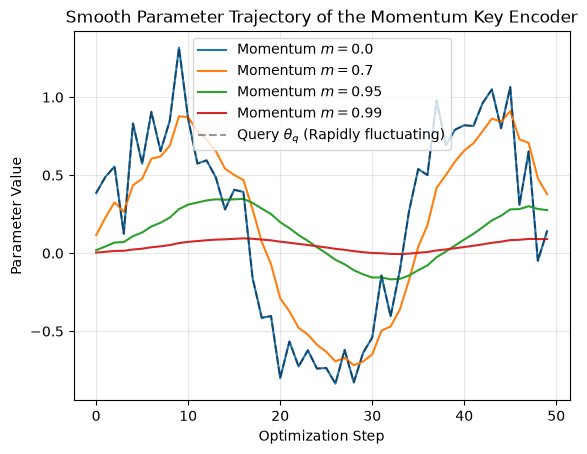

In [2]:
torch.manual_seed(42)

# Simulate a trajectory of fluctuating query encoder weights
steps = 50
theta_q_history = torch.sin(torch.linspace(0, 3 * math.pi, steps)) + 0.2 * torch.randn(steps)

for m in [0.0, 0.7, 0.95, 0.99]:
    theta_k = 0.0
    theta_k_history = []
    for t in range(steps):
        theta_k = m * theta_k + (1 - m) * theta_q_history[t].item()
        theta_k_history.append(theta_k)
    plt.plot(theta_k_history, label=f"Momentum $m = {m}$")

plt.plot(theta_q_history.numpy(), "k--", alpha=0.4, label="Query $\\theta_q$ (Rapidly fluctuating)")
plt.xlabel("Optimization Step")
plt.ylabel("Parameter Value")
plt.title("Smooth Parameter Trajectory of the Momentum Key Encoder")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

---
## 2. Dynamic FIFO Negative Queue
In MoCo, negative representations are kept in a fixed-size buffer ($K$). As new minibatches arrive, keys are enqueued while the oldest keys are dequeued.

In [3]:
dim = 16
K = 32
model = MoCo(dim=dim, K=K)

print(f"Initial queue shape: {model.queue.shape} (dim x K)")
print(f"Initial queue pointer: {model.queue_ptr[0].item()}")

# Push a batch of 8 keys
batch_keys = torch.ones(8, dim)
model._dequeue_and_enqueue(batch_keys)
print(f"Queue pointer after 8 keys: {model.queue_ptr[0].item()}")

# Push another batch of 16 keys
batch_keys2 = torch.full((16, dim), 2.0)
model._dequeue_and_enqueue(batch_keys2)
print(f"Queue pointer after 16 more keys: {model.queue_ptr[0].item()}")

# Push another batch of 16 keys (triggering wrap-around)
batch_keys3 = torch.full((16, dim), 3.0)
model._dequeue_and_enqueue(batch_keys3)
print(f"Queue pointer after wrap-around: {model.queue_ptr[0].item()}")

Initial queue shape: torch.Size([16, 32]) (dim x K)
Initial queue pointer: 0
Queue pointer after 8 keys: 8
Queue pointer after 16 more keys: 24
Queue pointer after wrap-around: 8


---
## 3. Training MoCo on Multi-View Image Clusters
Let's train MoCo on synthetic image instances and monitor the convergence of InfoNCE loss and contrastive accuracy.

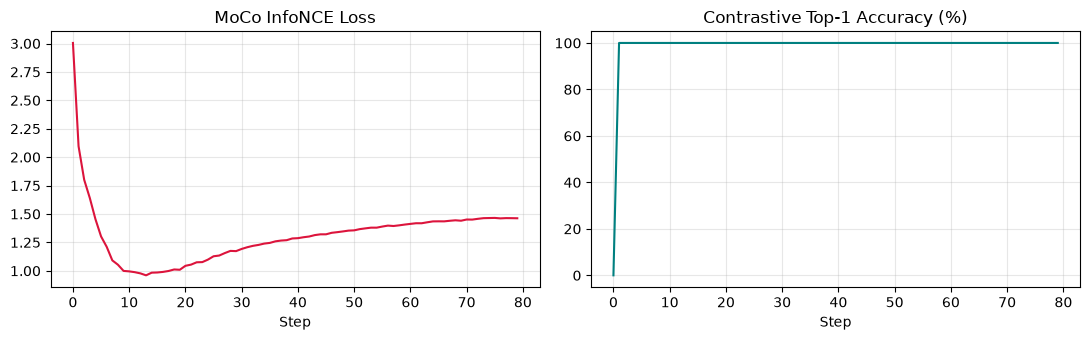

In [4]:
torch.manual_seed(42)
N = 8
dim = 32
K = 32

base_images = torch.randn(N, 3, 16, 16)
model = MoCo(dim=dim, K=K, m=0.99, T=0.1)
optimizer = torch.optim.AdamW(model.encoder_q.parameters(), lr=3e-3)

# Warm up queue with initial representations
with torch.no_grad():
    for _ in range(K // N + 1):
        wq = base_images + 0.05 * torch.randn_like(base_images)
        wk = base_images + 0.05 * torch.randn_like(base_images)
        model(wq, wk)

losses, accuracies = [], []
for step in range(80):
    optimizer.zero_grad()
    im_q = base_images + 0.05 * torch.randn_like(base_images)
    im_k = base_images + 0.05 * torch.randn_like(base_images)

    logits, labels = model(im_q, im_k)
    loss = F.cross_entropy(logits, labels)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    acc = (logits.argmax(dim=-1) == labels).float().mean().item()
    accuracies.append(acc * 100)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(losses, color="crimson")
axes[0].set_title("MoCo InfoNCE Loss")
axes[0].set_xlabel("Step")
axes[0].grid(True, alpha=0.3)

axes[1].plot(accuracies, color="teal")
axes[1].set_title("Contrastive Top-1 Accuracy (%)")
axes[1].set_xlabel("Step")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 4. Positive vs. Queued Negative Logits Distribution
In a trained MoCo model, positive cosine similarities (index 0) are distinctly elevated compared to the entire distribution of queued negative distractors.

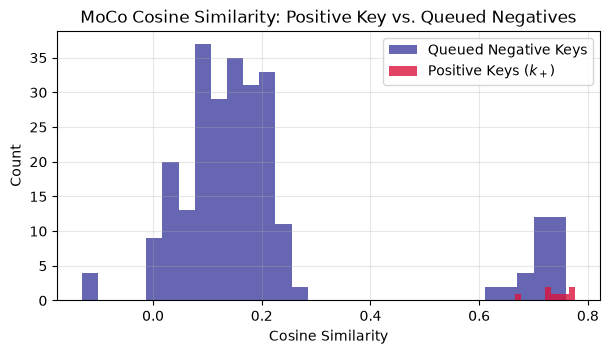

In [5]:
model.eval()
with torch.no_grad():
    im_q = base_images + 0.05 * torch.randn_like(base_images)
    im_k = base_images + 0.05 * torch.randn_like(base_images)
    logits, labels = model(im_q, im_k)

pos_logits = (logits[:, 0] * model.T).cpu().numpy()
neg_logits = (logits[:, 1:] * model.T).cpu().flatten().numpy()

plt.figure(figsize=(7, 3.5))
plt.hist(neg_logits, bins=30, alpha=0.6, color="navy", label="Queued Negative Keys")
plt.hist(pos_logits, bins=10, alpha=0.8, color="crimson", label="Positive Keys ($k_+$)")
plt.xlabel("Cosine Similarity")
plt.ylabel("Count")
plt.title("MoCo Cosine Similarity: Positive Key vs. Queued Negatives")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()